# Proyek Akhir IF5152 Visi Komputer

**_Transfer Learning_ pada Data Terbatas dan Gangguan Visual**

| | |
|---|---|
| Nama | Carlo Angkisan |
| NIM | 13523091 |
| Kartu | K09 |
| *Backbone* | MobileNetV2, bobot `IMAGENET1K_V1` |
| Resolusi *input* | 128×128 |
| Augmentasi *training* | *Rotation*, *Brightness* |

*Notebook* ini mempunyai dua mode, yaitu:

- `TRAIN`: membuat *split*, mengekstrak fitur dengan *backbone* beku, melatih 12 *linear head* (E1–E4 × 3 *seed*), lalu mengevaluasi pada tujuh kondisi *test*.
- `VERIFY`: tidak melatih apa pun. *Notebook* memuat *split manifest*, *cache* fitur, dan *checkpoint* yang sudah ada, lalu menghitung ulang prediksi dan metrik untuk dicocokkan dengan CSV.

## 1. Identitas dan kartu

In [1]:
STUDENT_ID = "13523091"
CARD_ID = "K09"
BACKBONE = "mobilenet_v2"
WEIGHTS = "IMAGENET1K_V1"
INPUT_SIZE = 128
AUGMENTATION = ("rotation", "brightness")

## 2. Konfigurasi

In [2]:
MODE = "TRAIN"  # "TRAIN" atau "VERIFY"

NUM_CLASSES = 10

# split
SPLIT_SEED = 2026
TEST_SPLIT_SEED = 3026
N_TRAIN_PER_CLASS = 100
N_VAL_PER_CLASS = 50
N_LOW_PER_CLASS = 25
N_TEST_PER_CLASS = 100

# preprocessing
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

# augmentasi training
AUG_SEED = 2026
ROTATION_RANGE = (-10.0, 10.0)
BRIGHTNESS_RANGE = (0.7, 1.3)

# kondisi test
BLUR_KERNEL = 5
TEST_CONDITIONS = {
    "bersih": None,
    "gelap_ringan": ("brightness", 0.8),
    "gelap_sedang": ("brightness", 0.6),
    "blur_ringan": ("blur", 0.6),
    "blur_sedang": ("blur", 1.2),
    "rotasi_ringan": ("rotation", 10.0),
    "rotasi_sedang": ("rotation", 20.0),
}

# training linear head
TRAINING_SEEDS = (11, 22, 33)
EXPERIMENTS = {
    "E1": {"low_data": True, "augment": False},
    "E2": {"low_data": True, "augment": True},
    "E3": {"low_data": False, "augment": False},
    "E4": {"low_data": False, "augment": True},
}
OPTIMIZER = "Adam"
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0
BATCH_SIZE = 64
EPOCHS = 30
SHUFFLE_SEED_OFFSET = 1000

# ekstraksi fitur
EXTRACT_BATCH_SIZE = 64
CHUNK_SIZE = 250

*Mount* Google Drive dan siapkan folder penyimpanan hasil.

In [3]:
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")
PROJECT_DIR = Path("/content/drive/MyDrive/13523091_FinalCV")
DATA_DIR = Path("/content/data")

CACHE_DIR = PROJECT_DIR / "feature_cache"
CKPT_DIR = PROJECT_DIR / "checkpoints"
LOG_DIR = PROJECT_DIR / "logs"
FIG_DIR = PROJECT_DIR / "figures"
for d in (PROJECT_DIR, DATA_DIR, CACHE_DIR, CKPT_DIR, LOG_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

print("PROJECT_DIR:", PROJECT_DIR)

Mounted at /content/drive
PROJECT_DIR: /content/drive/MyDrive/13523091_FinalCV


## 3. *Environment* dan *seed*

Atur *seed*, pilih *device*, dan catat versi *library* serta perangkat yang dipakai.

In [4]:
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import json
import platform
import random
import time
from datetime import datetime, timedelta, timezone

import numpy as np
import pandas as pd
import sklearn
import torch
import torchvision

WIB = timezone(timedelta(hours=7))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
HEAD_DEVICE = torch.device("cpu")

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True, warn_only=True)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def cpu_name():
    with open("/proc/cpuinfo") as f:
        for line in f:
            if line.startswith("model name"):
                return line.split(":", 1)[1].strip()


ENV_INFO = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "numpy": np.__version__,
    "scikit_learn": sklearn.__version__,
    "cpu": cpu_name(),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "start_time": datetime.now(WIB).isoformat(timespec="seconds"),
    "end_time": None,
}
print(json.dumps(ENV_INFO, indent=2))

{
  "python": "3.13.18",
  "torch": "2.14.1+cpu",
  "torchvision": "0.29.1+cpu",
  "numpy": "2.4.6",
  "scikit_learn": "1.6.1",
  "cpu": "Intel(R) Xeon(R) CPU @ 2.20GHz",
  "gpu": null,
  "start_time": "2026-11-26T06:31:03+07:00",
  "end_time": null
}


## 4. Unduh *dataset*

Unduh CIFAR-10 dari torchvision. Jika terdapat *Error* unduhan akan tercatat di `logs/download_errors.log`.

In [5]:
from torchvision.datasets import CIFAR10


def load_cifar10(train):
    try:
        return CIFAR10(root=DATA_DIR, train=train, download=True)
    except Exception as e:
        with open(LOG_DIR / "download_errors.log", "a") as f:
            f.write(f"{datetime.now(WIB).isoformat(timespec='seconds')} train={train} {e!r}\n")
        raise


train_set = load_cifar10(train=True)
test_set = load_cifar10(train=False)
CLASS_NAMES = list(train_set.classes)

print("train resmi:", len(train_set), "| test resmi:", len(test_set))
print("urutan kelas:", CLASS_NAMES)

100%|██████████| 170M/170M [00:27<00:00, 6.12MB/s]


train resmi: 50000 | test resmi: 10000
urutan kelas: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 5. Buat dan periksa *split*

Data dibagi per kelas dengan langkah berikut:

1. Kelompokkan indeks *train* resmi per kelas, urutkan, lalu acak dengan `default_rng(2026 + class_id)`.
2. Ambil 100 indeks pertama untuk *train* dan 50 berikutnya untuk *validation*. 25 indeks pertama dari *train* menjadi *train* terbatas.
3. Untuk *test* resmi, acak dengan `default_rng(3026 + class_id)` lalu ambil 100 indeks pertama per kelas.

Baris di *manifest* diurutkan per *subset* berdasarkan `original_index`. Urutan ini juga dipakai di *cache* dan `predictions.csv`.

In [6]:
# ambil indeks acak per kelas
def split_official(targets, seed_base, n_first, n_second=0):
    targets = np.asarray(targets)
    first, second = {}, {}
    for class_id in range(NUM_CLASSES):
        idx = np.sort(np.flatnonzero(targets == class_id))
        rng = np.random.default_rng(seed_base + class_id)
        perm = rng.permutation(idx)
        first[class_id] = perm[:n_first]
        second[class_id] = perm[n_first:n_first + n_second]
    return first, second


train_full, val = split_official(train_set.targets, SPLIT_SEED, N_TRAIN_PER_CLASS, N_VAL_PER_CLASS)
test, _ = split_official(test_set.targets, TEST_SPLIT_SEED, N_TEST_PER_CLASS)
low_data = {c: train_full[c][:N_LOW_PER_CLASS] for c in range(NUM_CLASSES)}
low_data_set = set(np.concatenate(list(low_data.values())).tolist())


def manifest_rows(groups, official_split, subset):
    rows = []
    for class_id, indices in groups.items():
        for i in indices:
            i = int(i)
            rows.append({
                "sample_id": f"{official_split}_{i:05d}",
                "official_split": official_split,
                "original_index": i,
                "class_id": class_id,
                "subset": subset,
                "is_low_data": int(subset == "train" and i in low_data_set),
            })
    return sorted(rows, key=lambda r: r["original_index"])


split_df = pd.DataFrame(
    manifest_rows(train_full, "train", "train")
    + manifest_rows(val, "train", "val")
    + manifest_rows(test, "test", "test")
)
split_df.head()

,sample_id,official_split,original_index,class_id,subset,is_low_data
0,train_00059,train,59,3,train,0
1,train_00078,train,78,3,train,1
2,train_00096,train,96,1,train,0
3,train_00208,train,208,9,train,0
4,train_00346,train,346,4,train,0


Cek hasil *split*: jumlah per kelas, tidak ada irisan, dan label sesuai dataset.

In [7]:
tr = split_df[split_df.subset == "train"]
va = split_df[split_df.subset == "val"]
te = split_df[split_df.subset == "test"]
lo = tr[tr.is_low_data == 1]

# jumlah per kelas
assert (tr.class_id.value_counts() == N_TRAIN_PER_CLASS).all() and tr.class_id.nunique() == NUM_CLASSES
assert (va.class_id.value_counts() == N_VAL_PER_CLASS).all() and va.class_id.nunique() == NUM_CLASSES
assert (lo.class_id.value_counts() == N_LOW_PER_CLASS).all() and lo.class_id.nunique() == NUM_CLASSES
assert (te.class_id.value_counts() == N_TEST_PER_CLASS).all() and te.class_id.nunique() == NUM_CLASSES

# train dan val tidak beririsan
assert set(tr.original_index).isdisjoint(va.original_index)
assert set(lo.original_index) <= set(tr.original_index)

# sumber split resmi
assert (tr.official_split == "train").all() and (va.official_split == "train").all()
assert (te.official_split == "test").all()

# label cocok dengan dataset
assert all(train_set.targets[i] == c for i, c in zip(tr.original_index, tr.class_id))
assert all(train_set.targets[i] == c for i, c in zip(va.original_index, va.class_id))
assert all(test_set.targets[i] == c for i, c in zip(te.original_index, te.class_id))

assert split_df.sample_id.is_unique
print("Split lolos semua pemeriksaan.")

counts = pd.DataFrame({
    "train_penuh": tr.class_id.value_counts().sort_index(),
    "train_terbatas": lo.class_id.value_counts().sort_index(),
    "validation": va.class_id.value_counts().sort_index(),
    "test": te.class_id.value_counts().sort_index(),
})
counts.index = [f"{i} {CLASS_NAMES[i]}" for i in counts.index]
counts.loc["total"] = counts.sum()
counts

Split lolos semua pemeriksaan.


,train_penuh,train_terbatas,validation,test
0 airplane,100,25,50,100
1 automobile,100,25,50,100
2 bird,100,25,50,100
3 cat,100,25,50,100
4 deer,100,25,50,100
5 dog,100,25,50,100
6 frog,100,25,50,100
7 horse,100,25,50,100
8 ship,100,25,50,100
9 truck,100,25,50,100


Simpan *manifest*. Kalau *file*-nya sudah ada, *split* dicocokkan dengan isi *file* tersebut.

In [8]:
MANIFEST_PATH = PROJECT_DIR / "split_manifest.csv"

if MANIFEST_PATH.exists():
    saved = pd.read_csv(MANIFEST_PATH)
    pd.testing.assert_frame_equal(saved, split_df)
    print("split_manifest.csv cocok dengan split yang dibuat ulang.")
elif MODE == "TRAIN":
    split_df.to_csv(MANIFEST_PATH, index=False)
    print("split_manifest.csv disimpan:", len(split_df), "baris")
else:
    raise FileNotFoundError("Mode VERIFY butuh split_manifest.csv dari run TRAIN.")

TRAIN_IDX = tr.original_index.to_numpy().copy()
LOW_MASK = tr.is_low_data.to_numpy().astype(bool)
VAL_IDX = va.original_index.to_numpy().copy()
TEST_IDX = te.original_index.to_numpy().copy()
TEST_SAMPLE_IDS = te.sample_id.to_numpy()

split_manifest.csv disimpan: 2500 baris


## 6. Visualisasi *preprocessing* dan augmentasi

Setiap citra diproses dengan urutan berikut.

1. Konversi ke RGB, lalu *resize* langsung dari 32×32 ke 128×128 (*bilinear*, `antialias=True`).
2. Konversi ke tensor dengan rentang 0–1.
3. Untuk *train* augmentasi, terapkan rotasi lalu *brightness*. Untuk *test* terganggu, terapkan satu gangguan sesuai kondisi.
4. Normalisasi dengan *mean* dan std ImageNet.

Parameter augmentasi tiap citra diambil dari `np.random.default_rng(2026 + original_index)`. Nilai pertama untuk sudut rotasi dan nilai kedua untuk faktor *brightness*.

In [9]:
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from torchvision.transforms import InterpolationMode


def load_resized(dataset, original_index):
    img = dataset[int(original_index)][0].convert("RGB")
    img = TF.resize(img, [INPUT_SIZE, INPUT_SIZE], interpolation=InterpolationMode.BILINEAR, antialias=True)
    return TF.to_tensor(img)


def apply_op(x, op, value):
    if op == "brightness":
        return TF.adjust_brightness(x, value)
    if op == "blur":
        return TF.gaussian_blur(x, [BLUR_KERNEL, BLUR_KERNEL], [value, value])
    if op == "rotation":
        return TF.rotate(x, value, interpolation=InterpolationMode.BILINEAR, fill=0.0)
    raise ValueError(op)


def sample_aug_params(original_index):
    rng = np.random.default_rng(AUG_SEED + int(original_index))
    angle = rng.uniform(*ROTATION_RANGE)
    factor = rng.uniform(*BRIGHTNESS_RANGE)
    return {"rotation": float(angle), "brightness": float(factor)}


def augment(x, params):
    for op in AUGMENTATION:
        x = apply_op(x, op, params[op])
    return x


# kind: None = bersih, "augment" = train augmentasi, (op, value) = test terganggu
def make_input(dataset, original_index, kind):
    x = load_resized(dataset, original_index)
    params = None
    if kind == "augment":
        params = sample_aug_params(original_index)
        x = augment(x, params)
    elif kind is not None:
        x = apply_op(x, *kind)
    return TF.normalize(x, IMAGENET_MEAN, IMAGENET_STD), params

Contoh enam citra *train* pertama berupa citra asli 32×32, hasil *resize*, dan versi augmentasinya.

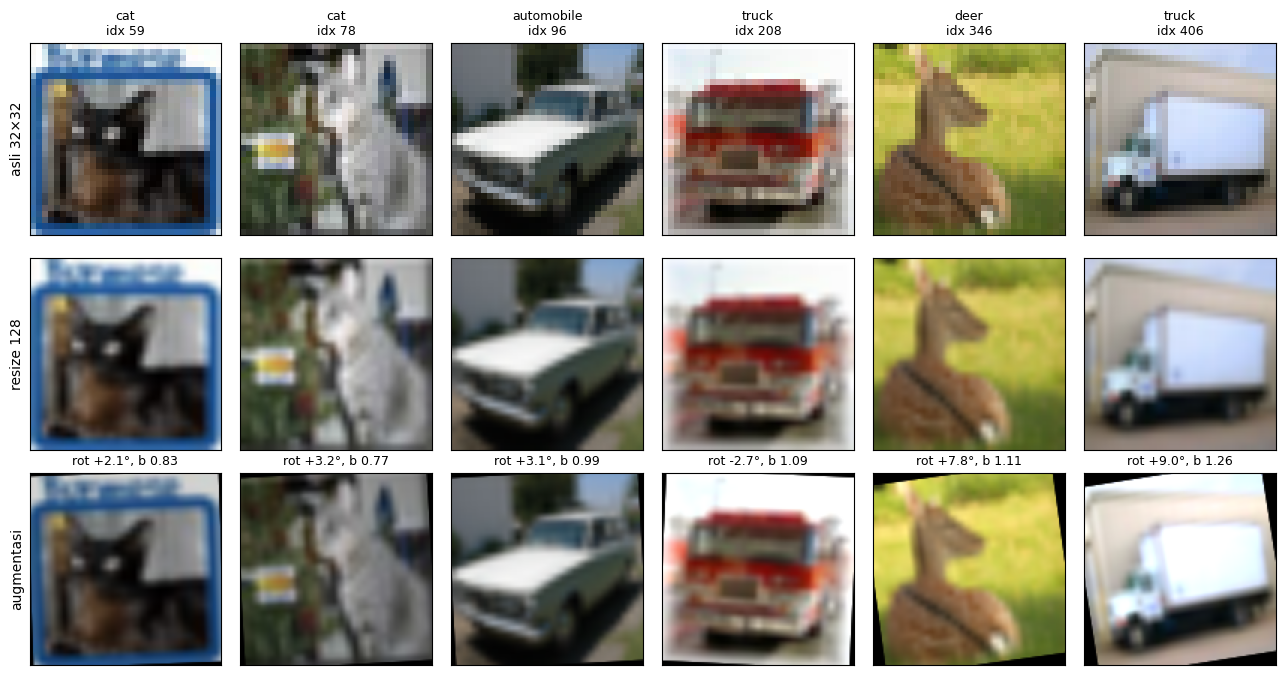

In [10]:
fig, axes = plt.subplots(3, 6, figsize=(13, 6.8))
for j, idx in enumerate(TRAIN_IDX[:6]):
    params = sample_aug_params(idx)
    clean = load_resized(train_set, idx)
    axes[0, j].imshow(train_set[int(idx)][0])
    axes[0, j].set_title(f"{CLASS_NAMES[train_set.targets[idx]]}\nidx {idx}", fontsize=9)
    axes[1, j].imshow(clean.permute(1, 2, 0))
    axes[2, j].imshow(augment(clean, params).permute(1, 2, 0))
    axes[2, j].set_title(f"rot {params['rotation']:+.1f}°, b {params['brightness']:.2f}", fontsize=9)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
for ax, label in zip(axes[:, 0], ["asli 32×32", "resize 128", "augmentasi"]):
    ax.set_ylabel(label)
plt.tight_layout()
plt.savefig(FIG_DIR / "preprocessing_augmentasi.png", dpi=150)
plt.show()

Tujuh kondisi *test* pada citra *test* pertama. Tiap gangguan diterapkan sendiri ke citra bersih hasil *resize*.

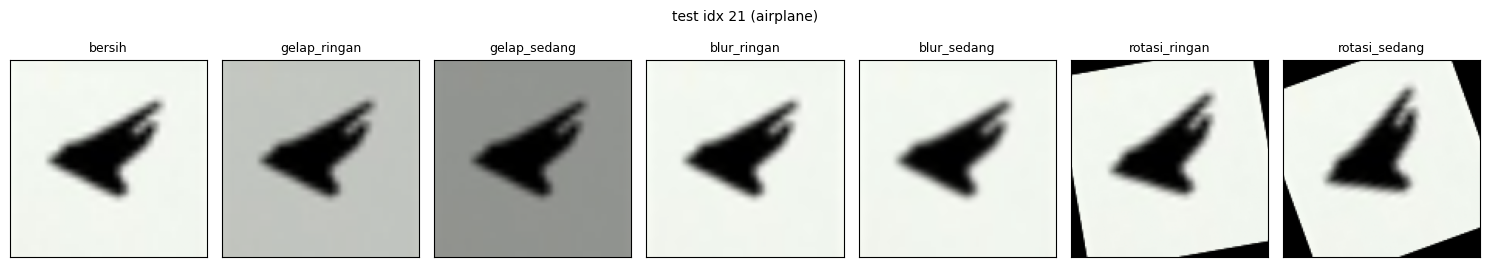

In [11]:
idx = TEST_IDX[0]
clean = load_resized(test_set, idx)
fig, axes = plt.subplots(1, len(TEST_CONDITIONS), figsize=(15, 2.8))
for ax, (cond, kind) in zip(axes, TEST_CONDITIONS.items()):
    x = clean if kind is None else apply_op(clean, *kind)
    ax.imshow(x.permute(1, 2, 0).clamp(0, 1))
    ax.set_title(cond, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle(f"test idx {idx} ({CLASS_NAMES[test_set.targets[idx]]})", fontsize=10)
plt.tight_layout()
plt.savefig(FIG_DIR / "kondisi_test.png", dpi=150)
plt.show()

## 7. Ekstrak dan simpan fitur

*Classifier* bawaan MobileNetV2 dibuang dan semua parameternya dibekukan. Model dijalankan dengan `eval()` dan `torch.inference_mode()`. Fitur diambil dari keluaran `features` lalu diringkas dengan *global average pooling* menjadi vektor 1280 dimensi.

Ada 10 *cache* yang dibuat.

| *Cache* | Sumber | Jumlah |
|---|---|---|
| `train_clean` | *train* penuh, bersih | 1000 |
| `train_aug` | *train* penuh, augmentasi | 1000 |
| `val_clean` | *validation*, bersih | 500 |
| `test_<kondisi>` | *test*, 7 kondisi | 7 × 1000 |

*Train* terbatas diambil dari `train_clean` dan `train_aug` memakai `is_low_data`.

*Cache* disimpan per *chunk* berisi maksimal 250 citra, dan indeks yang sudah selesai dicatat di `progress.json`. Kalau sesi terputus, jalankan ulang sel ini.

In [12]:
from torchvision.models import MobileNet_V2_Weights, mobilenet_v2

backbone = mobilenet_v2(weights=MobileNet_V2_Weights[WEIGHTS])
backbone.classifier = nn.Identity()  # head bawaan dibuang
for p in backbone.parameters():
    p.requires_grad_(False)
backbone = backbone.eval().to(DEVICE)

FEATURE_DIM = backbone.last_channel
backbone_state_before = {k: v.detach().clone() for k, v in backbone.state_dict().items()}


def extract_features(x):
    f = backbone.features(x)
    return F.adaptive_avg_pool2d(f, 1).flatten(1)


assert not backbone.training
assert not any(p.requires_grad for p in backbone.parameters())
print("feature_dim:", FEATURE_DIM, "| device:", DEVICE)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 47.3MB/s]


feature_dim: 1280 | device: cpu


In [13]:
CACHE_SPECS = {
    "train_clean": (train_set, TRAIN_IDX, None),
    "train_aug": (train_set, TRAIN_IDX, "augment"),
    "val_clean": (train_set, VAL_IDX, None),
}
for cond, kind in TEST_CONDITIONS.items():
    CACHE_SPECS[f"test_{cond}"] = (test_set, TEST_IDX, kind)


def n_chunks(indices):
    return (len(indices) + CHUNK_SIZE - 1) // CHUNK_SIZE


def extract_cache(name):
    dataset, indices, kind = CACHE_SPECS[name]
    out_dir = CACHE_DIR / name
    out_dir.mkdir(parents=True, exist_ok=True)
    progress_path = out_dir / "progress.json"
    done = set(json.loads(progress_path.read_text())) if progress_path.exists() else set()

    todo = [k for k in range(n_chunks(indices))
            if not set(indices[k * CHUNK_SIZE:(k + 1) * CHUNK_SIZE].tolist()) <= done]
    if not todo:
        print(f"{name:20s} sudah lengkap, dilewati")
        return

    t0 = time.time()
    for k in todo:
        chunk_idx = indices[k * CHUNK_SIZE:(k + 1) * CHUNK_SIZE]
        x = torch.stack([make_input(dataset, i, kind)[0] for i in chunk_idx])
        feats = []
        with torch.inference_mode():
            for b in range(0, len(x), EXTRACT_BATCH_SIZE):
                feats.append(extract_features(x[b:b + EXTRACT_BATCH_SIZE].to(DEVICE)).cpu())
        torch.save({
            "features": torch.cat(feats),
            "original_index": torch.as_tensor(chunk_idx),
            "labels": torch.as_tensor([dataset.targets[i] for i in chunk_idx]),
        }, out_dir / f"chunk_{k:03d}.pt")
        done.update(int(i) for i in chunk_idx)
        progress_path.write_text(json.dumps(sorted(done)))

    meta = {
        "backbone": BACKBONE,
        "weights": WEIGHTS,
        "input_size": INPUT_SIZE,
        "class_names": CLASS_NAMES,
        "torch": torch.__version__,
        "torchvision": torchvision.__version__,
        "original_index": [int(i) for i in indices],
        "labels": [int(dataset.targets[i]) for i in indices],
    }
    if kind == "augment":
        meta["aug_params"] = [sample_aug_params(i) for i in indices]
    (out_dir / "meta.json").write_text(json.dumps(meta))

    elapsed = time.time() - t0
    with open(LOG_DIR / "feature_extraction.log", "a") as f:
        f.write(f"{datetime.now(WIB).isoformat(timespec='seconds')} {name} chunks={todo} "
                f"device={DEVICE} seconds={elapsed:.1f}\n")
    print(f"{name:20s} selesai, chunk {todo} ({elapsed:.1f} s)")


# muat cache lalu cek urutan dan labelnya
def load_cache(name):
    dataset, indices, kind = CACHE_SPECS[name]
    out_dir = CACHE_DIR / name
    meta = json.loads((out_dir / "meta.json").read_text())
    assert meta["weights"] == WEIGHTS and meta["input_size"] == INPUT_SIZE
    assert meta["class_names"] == CLASS_NAMES
    chunks = [torch.load(out_dir / f"chunk_{k:03d}.pt") for k in range(n_chunks(indices))]
    feats = torch.cat([c["features"] for c in chunks])
    orig = torch.cat([c["original_index"] for c in chunks]).numpy()
    labels = torch.cat([c["labels"] for c in chunks])
    assert feats.dtype == torch.float32 and feats.shape == (len(indices), FEATURE_DIM)
    assert np.array_equal(orig, indices)
    assert labels.tolist() == [dataset.targets[i] for i in indices]
    return feats, labels

In [14]:
if MODE == "TRAIN":
    for name in CACHE_SPECS:
        extract_cache(name)

    # backbone tidak boleh berubah selama ekstraksi
    state_after = backbone.state_dict()
    assert all(torch.equal(v, state_after[k]) for k, v in backbone_state_before.items())
    print("Backbone tidak berubah selama ekstraksi.")

FEATURES = {}
for name in CACHE_SPECS:
    FEATURES[name] = load_cache(name)
    print(f"{name:20s} {tuple(FEATURES[name][0].shape)}")

train_clean          selesai, chunk [0, 1, 2, 3] (19.5 s)
train_aug            selesai, chunk [0, 1, 2, 3] (20.1 s)
val_clean            selesai, chunk [0, 1] (9.9 s)
test_bersih          selesai, chunk [0, 1, 2, 3] (19.2 s)
test_gelap_ringan    selesai, chunk [0, 1, 2, 3] (21.1 s)
test_gelap_sedang    selesai, chunk [0, 1, 2, 3] (19.3 s)
test_blur_ringan     selesai, chunk [0, 1, 2, 3] (19.7 s)
test_blur_sedang     selesai, chunk [0, 1, 2, 3] (20.9 s)
test_rotasi_ringan   selesai, chunk [0, 1, 2, 3] (19.9 s)
test_rotasi_sedang   selesai, chunk [0, 1, 2, 3] (20.4 s)
Backbone tidak berubah selama ekstraksi.
train_clean          (1000, 1280)
train_aug            (1000, 1280)
val_clean            (500, 1280)
test_bersih          (1000, 1280)
test_gelap_ringan    (1000, 1280)
test_gelap_sedang    (1000, 1280)
test_blur_ringan     (1000, 1280)
test_blur_sedang     (1000, 1280)
test_rotasi_ringan   (1000, 1280)
test_rotasi_sedang   (1000, 1280)


## 8. Latih E1–E4

| Kode | Data *train* | Kondisi *training* |
|---|---|---|
| E1 | 250 | bersih |
| E2 | 250 | bersih + augmentasi (rotasi, *brightness*) |
| E3 | 1000 | bersih |
| E4 | 1000 | bersih + augmentasi (rotasi, *brightness*) |

Aturan *fairness* yang dipakai adalah sebagai berikut.

- Tiap *seed* punya satu *head* awal yang disimpan di `checkpoints/head_init_seed{seed}.pt`, lalu dimuat ulang oleh E1–E4.
- *Seed* di-*reset* sebelum *head* dan DataLoader dibuat. *Shuffle* memakai generator terpisah dengan *seed* `training_seed + 1000`.
- E2 dan E4 memakai pasangan fitur bersih dan augmentasi dari `original_index` yang sama, dengan *loss* `0.5 * CE(bersih) + 0.5 * CE(aug)`.
- *Checkpoint* dipilih dari macro-F1 *validation* bersih tertinggi. Kalau seri, *epoch* yang lebih awal dipilih.

*Run* yang *checkpoint*-nya sudah ada akan dilewati.

In [15]:
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support
from torch.utils.data import DataLoader, TensorDataset

LABELS = list(range(NUM_CLASSES))

X_TRAIN_CLEAN, Y_TRAIN = FEATURES["train_clean"]
X_TRAIN_AUG, Y_TRAIN_AUG = FEATURES["train_aug"]
X_VAL, Y_VAL = FEATURES["val_clean"]
# urutan train_clean dan train_aug harus sama
assert torch.equal(Y_TRAIN, Y_TRAIN_AUG)

RUNS = [(exp_id, seed) for seed in TRAINING_SEEDS for exp_id in EXPERIMENTS]


def train_subset(low_data):
    mask = torch.from_numpy(LOW_MASK) if low_data else torch.ones(len(Y_TRAIN), dtype=torch.bool)
    return X_TRAIN_CLEAN[mask], X_TRAIN_AUG[mask], Y_TRAIN[mask]


def predict_logits(head, x):
    head.eval()
    with torch.inference_mode():
        return head(x.to(HEAD_DEVICE)).cpu()


def init_head_path(seed):
    return CKPT_DIR / f"head_init_seed{seed}.pt"


def ckpt_path(exp_id, seed):
    return CKPT_DIR / f"{exp_id}_seed{seed}.pt"

In [16]:
def train_run(exp_id, seed):
    cfg = EXPERIMENTS[exp_id]
    x_clean, x_aug, y = train_subset(cfg["low_data"])

    set_seed(seed)
    head = nn.Linear(FEATURE_DIM, NUM_CLASSES)
    head.load_state_dict(torch.load(init_head_path(seed)))
    head = head.to(HEAD_DEVICE)

    tensors = (x_clean, x_aug, y) if cfg["augment"] else (x_clean, y)
    loader = DataLoader(
        TensorDataset(*tensors), batch_size=BATCH_SIZE, shuffle=True,
        generator=torch.Generator().manual_seed(seed + SHUFFLE_SEED_OFFSET),
    )
    optimizer = torch.optim.Adam(head.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    criterion = nn.CrossEntropyLoss()

    history, best_f1, best_epoch, best_state = [], -1.0, None, None
    t0 = time.time()
    for epoch in range(1, EPOCHS + 1):
        head.train()
        loss_sum, n_seen = 0.0, 0
        for batch in loader:
            if cfg["augment"]:
                xc, xa, yb = batch
                loss = 0.5 * criterion(head(xc), yb) + 0.5 * criterion(head(xa), yb)
            else:
                xc, yb = batch
                loss = criterion(head(xc), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(yb)
            n_seen += len(yb)

        val_pred = predict_logits(head, X_VAL).argmax(1).numpy()
        val_f1 = f1_score(Y_VAL.numpy(), val_pred, labels=LABELS, average="macro", zero_division=0)
        val_acc = accuracy_score(Y_VAL.numpy(), val_pred)
        history.append({"epoch": epoch, "train_loss": loss_sum / n_seen,
                        "val_accuracy": val_acc, "val_macro_f1": val_f1})
        if val_f1 > best_f1:
            best_f1, best_epoch = val_f1, epoch
            best_state = {k: v.detach().clone() for k, v in head.state_dict().items()}
    seconds = time.time() - t0

    torch.save({
        "state_dict": best_state,
        "experiment_id": exp_id,
        "seed": seed,
        "best_epoch": best_epoch,
        "best_val_macro_f1": best_f1,
        "n_train": len(y),
        "training_seconds": round(seconds, 2),
    }, ckpt_path(exp_id, seed))
    pd.DataFrame(history).to_csv(LOG_DIR / f"train_{exp_id}_seed{seed}.csv", index=False)
    with open(LOG_DIR / "training.log", "a") as f:
        f.write(f"{datetime.now(WIB).isoformat(timespec='seconds')} {exp_id} seed={seed} n_train={len(y)} "
                f"best_epoch={best_epoch} best_val_macro_f1={best_f1:.4f} seconds={seconds:.1f}\n")
    print(f"{exp_id} seed {seed}: n_train={len(y)}, best epoch {best_epoch:2d}, "
          f"val macro-F1 {best_f1:.4f} ({seconds:.1f} s)")

In [17]:
if MODE == "TRAIN":
    for seed in TRAINING_SEEDS:
        if not init_head_path(seed).exists():
            set_seed(seed)
            torch.save(nn.Linear(FEATURE_DIM, NUM_CLASSES).state_dict(), init_head_path(seed))

    for exp_id, seed in RUNS:
        if ckpt_path(exp_id, seed).exists():
            print(f"{exp_id} seed {seed}: checkpoint sudah ada, dilewati")
            continue
        train_run(exp_id, seed)

E1 seed 11: n_train=250, best epoch 12, val macro-F1 0.7583 (0.5 s)
E2 seed 11: n_train=250, best epoch 17, val macro-F1 0.7514 (0.5 s)
E3 seed 11: n_train=1000, best epoch 14, val macro-F1 0.8059 (0.8 s)
E4 seed 11: n_train=1000, best epoch 13, val macro-F1 0.7973 (1.0 s)
E1 seed 22: n_train=250, best epoch 20, val macro-F1 0.7595 (0.3 s)
E2 seed 22: n_train=250, best epoch 27, val macro-F1 0.7511 (0.3 s)
E3 seed 22: n_train=1000, best epoch  8, val macro-F1 0.8078 (0.7 s)
E4 seed 22: n_train=1000, best epoch 10, val macro-F1 0.8002 (1.0 s)
E1 seed 33: n_train=250, best epoch 28, val macro-F1 0.7691 (0.3 s)
E2 seed 33: n_train=250, best epoch 19, val macro-F1 0.7651 (0.4 s)
E3 seed 33: n_train=1000, best epoch 25, val macro-F1 0.8139 (0.8 s)
E4 seed 33: n_train=1000, best epoch 14, val macro-F1 0.8042 (1.0 s)


Buat `experiment_manifest.csv` dari isi *checkpoint*, atau cocokkan dengan *file* yang sudah ada pada mode `VERIFY`.

In [18]:
rows = []
for exp_id, seed in RUNS:
    ck = torch.load(ckpt_path(exp_id, seed))
    assert ck["experiment_id"] == exp_id and ck["seed"] == seed
    rows.append({
        "student_id": STUDENT_ID,
        "card_id": CARD_ID,
        "experiment_id": exp_id,
        "seed": seed,
        "backbone": BACKBONE,
        "weights": WEIGHTS,
        "input_size": INPUT_SIZE,
        "augmentation": "+".join(AUGMENTATION) if EXPERIMENTS[exp_id]["augment"] else "none",
        "n_train": ck["n_train"],
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "optimizer": OPTIMIZER,
        "learning_rate": LEARNING_RATE,
        "best_epoch": ck["best_epoch"],
        "checkpoint_path": f"checkpoints/{ckpt_path(exp_id, seed).name}",
        "training_seconds": ck["training_seconds"],
    })
exp_df = pd.DataFrame(rows)

EXP_MANIFEST_PATH = PROJECT_DIR / "experiment_manifest.csv"
if MODE == "TRAIN":
    exp_df.to_csv(EXP_MANIFEST_PATH, index=False)
else:
    pd.testing.assert_frame_equal(pd.read_csv(EXP_MANIFEST_PATH, dtype={"student_id": str}), exp_df, check_dtype=False)
    print("experiment_manifest.csv cocok dengan checkpoint.")

exp_df[["experiment_id", "seed", "augmentation", "n_train", "best_epoch", "training_seconds"]]

,experiment_id,seed,augmentation,n_train,best_epoch,training_seconds
0,E1,11,none,250,12,0.45
1,E2,11,rotation+brightness,250,17,0.52
2,E3,11,none,1000,14,0.82
3,E4,11,rotation+brightness,1000,13,0.99
4,E1,22,none,250,20,0.28
5,E2,22,rotation+brightness,250,27,0.34
6,E3,22,none,1000,8,0.73
7,E4,22,rotation+brightness,1000,10,1.05
8,E1,33,none,250,28,0.29
9,E2,33,rotation+brightness,250,19,0.37


## 9. Evaluasi *test*

Tiap *checkpoint* dievaluasi pada tujuh kondisi *test* (12 × 7 = 84 baris metrik). Metrik dihitung dengan `labels=range(10)` dan `zero_division=0`, dan probabilitas disimpan dengan enam angka desimal. Pada mode `VERIFY`, hasilnya dicocokkan dengan `metrics.csv` dan `predictions.csv`.

In [19]:
def load_head(exp_id, seed):
    head = nn.Linear(FEATURE_DIM, NUM_CLASSES)
    head.load_state_dict(torch.load(ckpt_path(exp_id, seed))["state_dict"])
    return head.to(HEAD_DEVICE).eval()


PROB_COLS = [f"p{i}" for i in range(NUM_CLASSES)]
metric_rows, pred_frames = [], []
for exp_id, seed in RUNS:
    head = load_head(exp_id, seed)
    for cond in TEST_CONDITIONS:
        x, y = FEATURES[f"test_{cond}"]
        probs = torch.softmax(predict_logits(head, x), dim=1).numpy()
        y_true = y.numpy()
        y_pred = probs.argmax(1)
        prec, rec, f1, _ = precision_recall_fscore_support(
            y_true, y_pred, labels=LABELS, average="macro", zero_division=0)
        metric_rows.append({
            "student_id": STUDENT_ID, "card_id": CARD_ID, "experiment_id": exp_id, "seed": seed,
            "test_condition": cond, "n_test": len(y_true), "accuracy": accuracy_score(y_true, y_pred),
            "macro_precision": prec, "macro_recall": rec, "macro_f1": f1,
        })
        frame = pd.DataFrame({"experiment_id": exp_id, "seed": seed, "test_condition": cond,
                              "sample_id": TEST_SAMPLE_IDS, "y_true": y_true, "y_pred": y_pred})
        frame[PROB_COLS] = probs
        pred_frames.append(frame)

metrics_df = pd.DataFrame(metric_rows)
pred_df = pd.concat(pred_frames, ignore_index=True)
assert len(metrics_df) == len(EXPERIMENTS) * len(TRAINING_SEEDS) * len(TEST_CONDITIONS) == 84
assert len(pred_df) == 84 * len(TEST_IDX)
print(len(metrics_df), "baris metrik,", len(pred_df), "baris prediksi")

84 baris metrik, 84000 baris prediksi


In [20]:
METRICS_PATH = PROJECT_DIR / "metrics.csv"
PRED_PATH = PROJECT_DIR / "predictions.csv"

if MODE == "TRAIN":
    metrics_df.to_csv(METRICS_PATH, index=False)
    pred_df.to_csv(PRED_PATH, index=False, float_format="%.6f")
    print("metrics.csv dan predictions.csv disimpan.")

saved_metrics = pd.read_csv(METRICS_PATH, dtype={"student_id": str})
saved_pred = pd.read_csv(PRED_PATH)

# cocokkan dengan file
pd.testing.assert_frame_equal(saved_metrics, metrics_df, check_dtype=False, check_exact=False, rtol=0, atol=1e-12)
key_cols = ["experiment_id", "seed", "test_condition", "sample_id", "y_true", "y_pred"]
pd.testing.assert_frame_equal(saved_pred[key_cols], pred_df[key_cols], check_dtype=False)
max_prob_diff = np.abs(saved_pred[PROB_COLS].to_numpy() - pred_df[PROB_COLS].to_numpy()).max()
assert max_prob_diff <= 1e-6

# sample_id dan label harus sesuai manifest
manifest_labels = split_df.set_index("sample_id").class_id
assert saved_pred.sample_id.isin(manifest_labels.index).all()
assert (saved_pred.y_true.to_numpy() == manifest_labels.loc[saved_pred.sample_id].to_numpy()).all()

print(f"Prediksi dan metrik cocok dengan file (selisih probabilitas maks {max_prob_diff:.1e}).")

metrics.csv dan predictions.csv disimpan.
Prediksi dan metrik cocok dengan file (selisih probabilitas maks 5.0e-07).


Contoh penelusuran satu prediksi: sampel *test* pertama pada E4 *seed* 11 kondisi bersih, dari fitur di *cache* sampai baris di `predictions.csv` dan kontribusinya ke `metrics.csv`.

In [21]:
trace_exp, trace_seed, trace_cond = "E4", 11, "bersih"
trace_id = TEST_SAMPLE_IDS[0]
pos = int(np.flatnonzero(TEST_SAMPLE_IDS == trace_id)[0])

x, y = FEATURES[f"test_{trace_cond}"]
logits = predict_logits(load_head(trace_exp, trace_seed), x[pos:pos + 1])[0]
probs = torch.softmax(logits, 0).numpy()
print("sample_id    :", trace_id, "| original_index:", TEST_IDX[pos])
print("label        :", int(y[pos]), CLASS_NAMES[int(y[pos])])
print("probabilitas :", np.round(probs, 6))
print("prediksi     :", int(probs.argmax()), CLASS_NAMES[int(probs.argmax())])

row = saved_pred[(saved_pred.experiment_id == trace_exp) & (saved_pred.seed == trace_seed)
                 & (saved_pred.test_condition == trace_cond) & (saved_pred.sample_id == trace_id)]
print("\nbaris di predictions.csv:")
print(row.to_string(index=False))

g = saved_pred[(saved_pred.experiment_id == trace_exp) & (saved_pred.seed == trace_seed)
               & (saved_pred.test_condition == trace_cond)]
cm = confusion_matrix(g.y_true, g.y_pred, labels=LABELS)
c = int(y[pos])
print(f"\nkelas {CLASS_NAMES[c]}: TP={cm[c, c]}, FN={cm[c].sum() - cm[c, c]}, FP={cm[:, c].sum() - cm[c, c]}")
print(saved_metrics[(saved_metrics.experiment_id == trace_exp) & (saved_metrics.seed == trace_seed)
                    & (saved_metrics.test_condition == trace_cond)].to_string(index=False))

sample_id    : test_00021 | original_index: 21
label        : 0 airplane
probabilitas : [7.63486e-01 1.66000e-04 2.11182e-01 3.80800e-03 4.73800e-03 2.65400e-03
 1.03750e-02 2.09100e-03 1.32600e-03 1.74000e-04]
prediksi     : 0 airplane

baris di predictions.csv:
experiment_id  seed test_condition  sample_id  y_true  y_pred       p0       p1       p2       p3       p4       p5       p6       p7       p8       p9
           E4    11         bersih test_00021       0       0 0.763486 0.000166 0.211182 0.003808 0.004738 0.002654 0.010375 0.002091 0.001326 0.000174

kelas airplane: TP=84, FN=16, FP=24
student_id card_id experiment_id  seed test_condition  n_test  accuracy  macro_precision  macro_recall  macro_f1
  13523091     K09            E4    11         bersih    1000     0.796          0.79785         0.796  0.793105


## 10. Agregasi hasil

Semua angka dihitung dari `metrics.csv` dan `predictions.csv`, dalam persen. Selisih ditulis dalam *percentage points* (pp), dan std memakai `ddof=1` dari tiga *seed*. Tabel disimpan ke `figures/`.

In [22]:
METRIC_COLS = ["accuracy", "macro_precision", "macro_recall", "macro_f1"]
COND_ORDER = list(TEST_CONDITIONS)
PERTURBATIONS = COND_ORDER[1:]
m = saved_metrics.copy()
m[METRIC_COLS] = m[METRIC_COLS] * 100


def mean_std(s):
    return f"{s.mean():.2f} ± {s.std(ddof=1):.2f}"


# jumlah sampel
counts.to_csv(FIG_DIR / "tabel_jumlah_sampel.csv")

# hasil test bersih
clean = m[m.test_condition == "bersih"]
table_clean = clean.groupby("experiment_id")[METRIC_COLS].agg(mean_std)
table_clean.to_csv(FIG_DIR / "tabel_hasil_bersih.csv")
print("Test bersih, mean ± std (%):")
display(table_clean)

print("Macro-F1 test bersih per seed (%):")
f1_clean_seed = clean.pivot(index="experiment_id", columns="seed", values="macro_f1").round(2)
f1_clean_seed.to_csv(FIG_DIR / "tabel_f1_bersih_per_seed.csv")
display(f1_clean_seed)

Test bersih, mean ± std (%):


,accuracy,macro_precision,macro_recall,macro_f1
experiment_id,,,,
E1,74.67 ± 0.06,74.71 ± 0.09,74.67 ± 0.06,74.51 ± 0.01
E2,72.80 ± 0.26,72.88 ± 0.45,72.80 ± 0.26,72.42 ± 0.24
E3,78.70 ± 0.20,78.77 ± 0.14,78.70 ± 0.20,78.53 ± 0.21
E4,79.43 ± 0.15,79.58 ± 0.21,79.43 ± 0.15,79.20 ± 0.10


Macro-F1 test bersih per seed (%):


seed,11,22,33
experiment_id,,,
E1,74.51,74.52,74.50
E2,72.49,72.16,72.63
E3,78.72,78.57,78.30
E4,79.31,79.18,79.11


In [23]:
# macro-F1 per kondisi
table_cond = m.groupby(["experiment_id", "test_condition"]).macro_f1.agg(mean_std).unstack()[COND_ORDER]
table_cond.to_csv(FIG_DIR / "tabel_f1_kondisi.csv")
print("Macro-F1 per kondisi test, mean ± std (%):")
display(table_cond)

# ΔF1 per seed
f1_wide = m.pivot_table(index=["experiment_id", "seed"], columns="test_condition", values="macro_f1")
delta = f1_wide[PERTURBATIONS].rsub(f1_wide["bersih"], axis=0)
delta_long = delta.reset_index().melt(id_vars=["experiment_id", "seed"], var_name="test_condition", value_name="delta_f1_pp")
table_delta = delta_long.groupby(["experiment_id", "test_condition"]).delta_f1_pp.agg(mean_std).unstack()[PERTURBATIONS]
table_delta.to_csv(FIG_DIR / "tabel_delta_f1.csv")
print("ΔF1 = F1_bersih − F1_terganggu, mean ± std (pp):")
display(table_delta)

Macro-F1 per kondisi test, mean ± std (%):


test_condition,bersih,gelap_ringan,gelap_sedang,blur_ringan,blur_sedang,rotasi_ringan,rotasi_sedang
experiment_id,,,,,,,
E1,74.51 ± 0.01,73.96 ± 0.04,71.19 ± 0.51,74.35 ± 0.50,72.44 ± 0.13,43.80 ± 0.67,27.42 ± 0.16
E2,72.42 ± 0.24,71.81 ± 0.19,70.17 ± 0.68,72.18 ± 0.50,71.30 ± 0.66,60.80 ± 0.66,48.43 ± 0.97
E3,78.53 ± 0.21,77.79 ± 0.47,74.80 ± 0.88,78.09 ± 0.94,76.79 ± 0.74,37.77 ± 2.38,23.61 ± 0.34
E4,79.20 ± 0.10,77.55 ± 0.32,74.58 ± 0.45,78.22 ± 0.38,76.45 ± 0.90,67.85 ± 0.30,54.73 ± 1.96


ΔF1 = F1_bersih − F1_terganggu, mean ± std (pp):


test_condition,gelap_ringan,gelap_sedang,blur_ringan,blur_sedang,rotasi_ringan,rotasi_sedang
experiment_id,,,,,,
E1,0.55 ± 0.05,3.32 ± 0.49,0.16 ± 0.50,2.07 ± 0.14,30.71 ± 0.67,47.09 ± 0.16
E2,0.62 ± 0.22,2.25 ± 0.79,0.24 ± 0.72,1.13 ± 0.44,11.63 ± 0.50,23.99 ± 0.79
E3,0.74 ± 0.54,3.73 ± 0.81,0.44 ± 0.86,1.74 ± 0.73,40.76 ± 2.30,54.92 ± 0.47
E4,1.65 ± 0.40,4.62 ± 0.50,0.98 ± 0.47,2.75 ± 0.97,11.36 ± 0.29,24.47 ± 1.90


Konsistensi arah perbedaan antar-*seed*. Setiap perbandingan dihitung per *seed*, misalnya E2 − E1 pada *seed* 11, 22, dan 33. Arahnya disebut konsisten kalau ketiga selisih punya tanda yang sama.

In [24]:
f1_by_seed = m.pivot_table(index=["test_condition", "seed"], columns="experiment_id", values="macro_f1")
COMPARISONS = {
    "E2-E1 (augmentasi, 250)": ("E2", "E1"),
    "E4-E3 (augmentasi, 1000)": ("E4", "E3"),
    "E3-E1 (data, tanpa augmentasi)": ("E3", "E1"),
    "E4-E2 (data, dengan augmentasi)": ("E4", "E2"),
}
cons_rows = []
for label, (a, b) in COMPARISONS.items():
    for cond in COND_ORDER:
        d = (f1_by_seed.loc[cond, a] - f1_by_seed.loc[cond, b])
        signs = np.sign(d.to_numpy())
        cons_rows.append({
            "perbandingan": label, "test_condition": cond,
            **{f"seed_{s}": round(v, 2) for s, v in d.items()},
            "mean": round(d.mean(), 2),
            "konsisten": "ya" if (signs > 0).all() or (signs < 0).all() else "tidak",
        })
table_consistency = pd.DataFrame(cons_rows)
table_consistency.to_csv(FIG_DIR / "tabel_konsistensi_seed.csv", index=False)
table_consistency

,perbandingan,test_condition,seed_11,seed_22,seed_33,mean,konsisten
0,"E2-E1 (augmentasi, 250)",bersih,-2.02,-2.36,-1.87,-2.09,ya
1,"E2-E1 (augmentasi, 250)",gelap_ringan,-2.36,-2.16,-1.94,-2.16,ya
2,"E2-E1 (augmentasi, 250)",gelap_sedang,-1.42,-1.13,-0.50,-1.02,ya
3,"E2-E1 (augmentasi, 250)",blur_ringan,-1.60,-1.68,-3.23,-2.17,ya
4,"E2-E1 (augmentasi, 250)",blur_sedang,-0.92,-1.77,-0.75,-1.15,ya
5,"E2-E1 (augmentasi, 250)",rotasi_ringan,18.28,16.26,16.44,16.99,ya
6,"E2-E1 (augmentasi, 250)",rotasi_sedang,22.05,19.94,21.05,21.01,ya
7,"E4-E3 (augmentasi, 1000)",bersih,0.59,0.61,0.81,0.67,ya
8,"E4-E3 (augmentasi, 1000)",gelap_ringan,0.01,-0.98,0.26,-0.23,tidak
9,"E4-E3 (augmentasi, 1000)",gelap_sedang,0.01,-1.64,0.96,-0.23,tidak


Pasangan kelas yang paling sering tertukar pada *test* bersih. Jumlahnya dijumlahkan dari tiga *seed*, dan pasangan dihitung dua arah (A→B dan B→A digabung).

In [25]:
conf_rows = []
for exp_id in EXPERIMENTS:
    g = saved_pred[(saved_pred.experiment_id == exp_id) & (saved_pred.test_condition == "bersih")]
    cm = confusion_matrix(g.y_true, g.y_pred, labels=LABELS)
    pair = cm + cm.T
    for i in range(NUM_CLASSES):
        for j in range(i + 1, NUM_CLASSES):
            conf_rows.append({"experiment_id": exp_id, "kelas_a": CLASS_NAMES[i], "kelas_b": CLASS_NAMES[j],
                              "a_ke_b": cm[i, j], "b_ke_a": cm[j, i], "total": pair[i, j]})
confused = (pd.DataFrame(conf_rows).sort_values(["experiment_id", "total"], ascending=[True, False])
            .groupby("experiment_id").head(5))
confused.to_csv(FIG_DIR / "tabel_kelas_tertukar.csv", index=False)
confused

,experiment_id,kelas_a,kelas_b,a_ke_b,b_ke_a,total
25,E1,cat,dog,47,38,85
32,E1,deer,horse,35,40,75
7,E1,airplane,ship,33,39,72
16,E1,automobile,truck,29,18,47
20,E1,bird,frog,35,10,45
70,E2,cat,dog,44,36,80
77,E2,deer,horse,41,35,76
65,E2,bird,frog,46,11,57
52,E2,airplane,ship,25,27,52
81,E2,dog,horse,33,17,50


## 11. Buat visualisasi

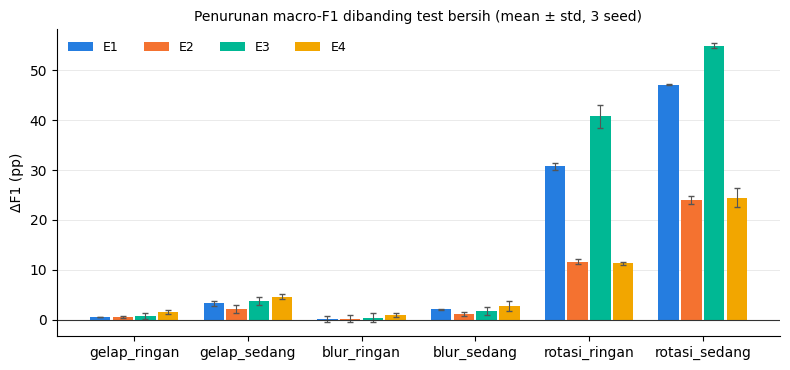

In [26]:
EXP_COLORS = {"E1": "#257de0", "E2": "#f47230", "E3": "#00b894", "E4": "#f2a600"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
                     "grid.color": "#e6e6e6", "grid.linewidth": 0.6, "axes.axisbelow": True})

# grafik ΔF1
fig, ax = plt.subplots(figsize=(8, 3.8))
width = 0.2
xpos = np.arange(len(PERTURBATIONS))
for k, exp_id in enumerate(EXPERIMENTS):
    d = delta.loc[exp_id]
    ax.bar(xpos + (k - 1.5) * width, d.mean(), width * 0.9, yerr=d.std(ddof=1), capsize=2,
           color=EXP_COLORS[exp_id], label=exp_id, error_kw={"elinewidth": 0.8, "ecolor": "#555555"})
ax.axhline(0, color="#333333", linewidth=0.8)
ax.set_xticks(xpos, PERTURBATIONS)
ax.set_ylabel("ΔF1 (pp)")
ax.set_title("Penurunan macro-F1 dibanding test bersih (mean ± std, 3 seed)", fontsize=10)
ax.legend(ncol=4, frameon=False, fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / "delta_f1.png", dpi=200)
plt.show()

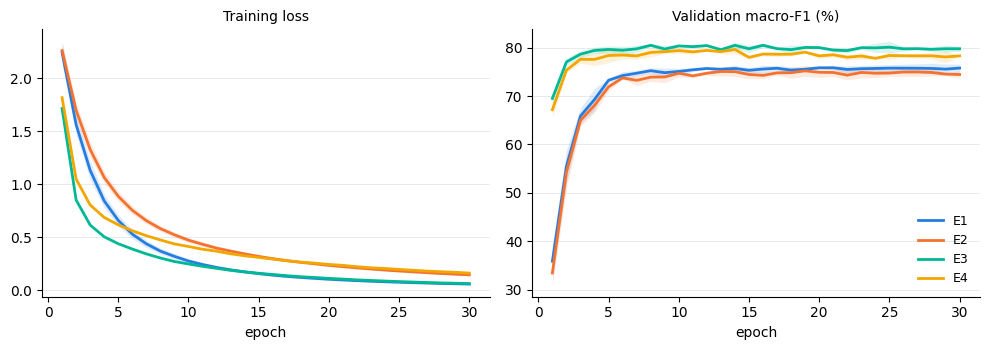

In [27]:
# kurva training
hist = pd.concat([
    pd.read_csv(LOG_DIR / f"train_{e}_seed{s}.csv").assign(experiment_id=e, seed=s) for e, s in RUNS
])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for exp_id in EXPERIMENTS:
    h = hist[hist.experiment_id == exp_id].groupby("epoch")
    for ax, col, scale in [(axes[0], "train_loss", 1), (axes[1], "val_macro_f1", 100)]:
        mu, sd = h[col].mean() * scale, h[col].std(ddof=1) * scale
        ax.plot(mu.index, mu, color=EXP_COLORS[exp_id], linewidth=2, label=exp_id)
        ax.fill_between(mu.index, mu - sd, mu + sd, color=EXP_COLORS[exp_id], alpha=0.15, linewidth=0)
axes[0].set_title("Training loss", fontsize=10)
axes[1].set_title("Validation macro-F1 (%)", fontsize=10)
for ax in axes:
    ax.set_xlabel("epoch")
axes[1].legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / "kurva_training.png", dpi=200)
plt.show()

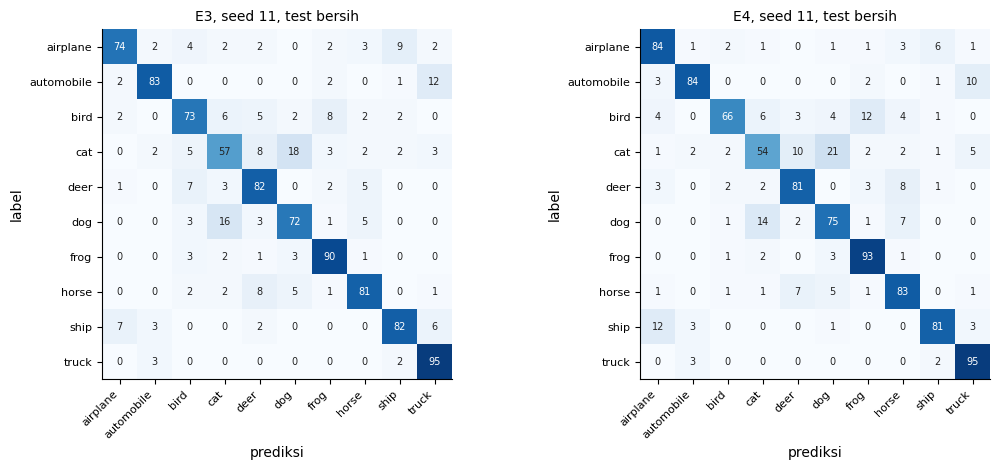

In [28]:
# confusion matrix E3 dan E4, seed 11
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, exp_id in zip(axes, ["E3", "E4"]):
    g = saved_pred[(saved_pred.experiment_id == exp_id) & (saved_pred.seed == 11)
                   & (saved_pred.test_condition == "bersih")]
    cm = confusion_matrix(g.y_true, g.y_pred, labels=LABELS)
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=N_TEST_PER_CLASS)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                    color="white" if cm[i, j] > 60 else "#222222")
    ax.set_xticks(LABELS, CLASS_NAMES, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(LABELS, CLASS_NAMES, fontsize=8)
    ax.set_xlabel("prediksi")
    ax.set_ylabel("label")
    ax.grid(False)
    ax.set_title(f"{exp_id}, seed 11, test bersih", fontsize=10)
plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrix_E3_E4.png", dpi=200)
plt.show()

Dua belas sampel *test* pertama (urutan *manifest*) pada kondisi bersih dan tiga gangguan tingkat sedang, dengan prediksi dari E4 *seed* 11. Judul berwarna hijau berarti prediksi benar, merah berarti salah.

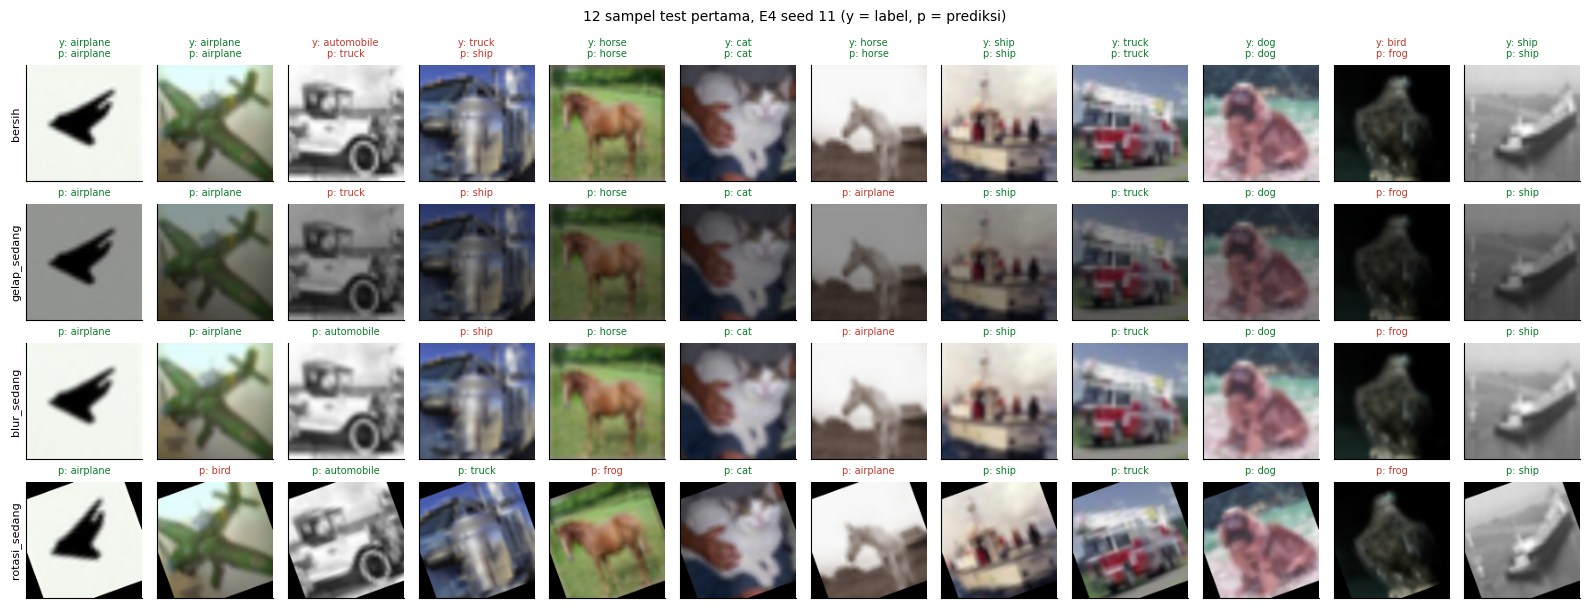

In [29]:
show_exp, show_seed = "E4", 11
show_conds = ["bersih", "gelap_sedang", "blur_sedang", "rotasi_sedang"]
first12 = TEST_SAMPLE_IDS[:12]
p = saved_pred[(saved_pred.experiment_id == show_exp) & (saved_pred.seed == show_seed)].set_index(["test_condition", "sample_id"])

fig, axes = plt.subplots(len(show_conds), 12, figsize=(16, 6.2))
for j, sid in enumerate(first12):
    idx = TEST_IDX[j]
    clean_img = load_resized(test_set, idx)
    for i, cond in enumerate(show_conds):
        kind = TEST_CONDITIONS[cond]
        img = clean_img if kind is None else apply_op(clean_img, *kind)
        r = p.loc[(cond, sid)]
        ax = axes[i, j]
        ax.imshow(img.permute(1, 2, 0).clamp(0, 1))
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        title = f"p: {CLASS_NAMES[int(r.y_pred)]}"
        if i == 0:
            title = f"y: {CLASS_NAMES[int(r.y_true)]}\n" + title
        ax.set_title(title, fontsize=7, color="#0a7d28" if r.y_pred == r.y_true else "#c0392b")
        if j == 0:
            ax.set_ylabel(cond, fontsize=8)
plt.suptitle(f"12 sampel test pertama, {show_exp} seed {show_seed} (y = label, p = prediksi)", fontsize=10)
plt.tight_layout()
plt.savefig(FIG_DIR / "sampel_test_pertama.png", dpi=200)
plt.show()

Enam kesalahan prediksi pertama (urutan *manifest*) dari E4 *seed* 11 pada *test* bersih.

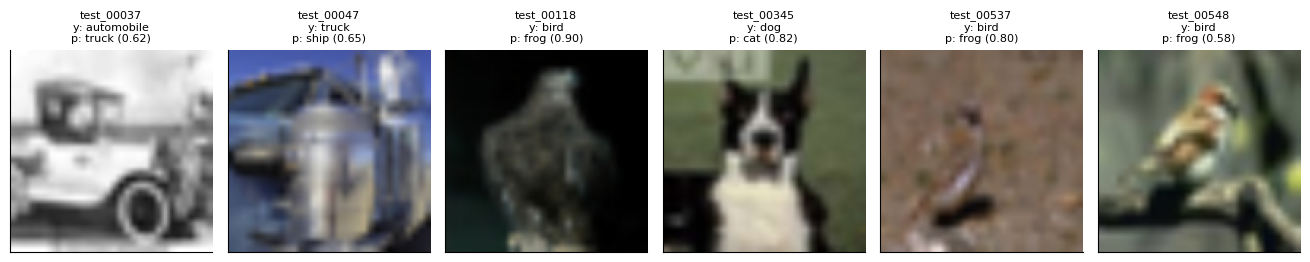

In [30]:
g = saved_pred[(saved_pred.experiment_id == show_exp) & (saved_pred.seed == show_seed)
               & (saved_pred.test_condition == "bersih")]
errors = g[g.y_true != g.y_pred].head(6)

fig, axes = plt.subplots(1, len(errors), figsize=(2.2 * len(errors), 2.8))
for ax, (_, r) in zip(np.atleast_1d(axes), errors.iterrows()):
    idx = int(r.sample_id.split("_")[1])
    ax.imshow(load_resized(test_set, idx).permute(1, 2, 0))
    conf = r[PROB_COLS].to_numpy(dtype=float).max()
    ax.set_title(f"{r.sample_id}\ny: {CLASS_NAMES[int(r.y_true)]}\np: {CLASS_NAMES[int(r.y_pred)]} ({conf:.2f})",
                 fontsize=8)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout()
plt.savefig(FIG_DIR / "contoh_kesalahan.png", dpi=200)
plt.show()

## 12. Periksa artefak

Cek semua *file* hasil sudah lengkap. Mode `TRAIN` menyimpan *checksum* tiap *file* beserta `environment.json` dan `requirements.txt`, sedangkan mode `VERIFY` mencocokkan *checksum* tersebut.

In [31]:
import hashlib

checks = {
    "12 checkpoint": all(ckpt_path(e, s).exists() for e, s in RUNS),
    "3 head awal": all(init_head_path(s).exists() for s in TRAINING_SEEDS),
    "split_manifest 2500 baris": len(pd.read_csv(MANIFEST_PATH)) == 2500,
    "experiment_manifest 12 baris": len(pd.read_csv(EXP_MANIFEST_PATH)) == 12,
    "metrics 84 baris": len(saved_metrics) == 84,
    "predictions 84000 baris": len(saved_pred) == 84000,
    "log training 12 run": all((LOG_DIR / f"train_{e}_seed{s}.csv").exists() for e, s in RUNS),
    "cache fitur lengkap": all((CACHE_DIR / n / "meta.json").exists() for n in CACHE_SPECS),
}
for name, ok in checks.items():
    print(f"[{'OK' if ok else 'GAGAL'}] {name}")
assert all(checks.values())

[OK] 12 checkpoint
[OK] 3 head awal
[OK] split_manifest 2500 baris
[OK] experiment_manifest 12 baris
[OK] metrics 84 baris
[OK] predictions 84000 baris
[OK] log training 12 run
[OK] cache fitur lengkap


In [32]:
def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()


checksum_files = [MANIFEST_PATH, EXP_MANIFEST_PATH, METRICS_PATH, PRED_PATH]
checksum_files += sorted(CKPT_DIR.glob("*.pt"))
for name in CACHE_SPECS:
    checksum_files += sorted((CACHE_DIR / name).glob("chunk_*.pt")) + [CACHE_DIR / name / "meta.json"]
CHECKSUM_PATH = PROJECT_DIR / "checksums.sha256"

if MODE == "TRAIN":
    ENV_INFO["end_time"] = datetime.now(WIB).isoformat(timespec="seconds")
    (PROJECT_DIR / "environment.json").write_text(json.dumps(ENV_INFO, indent=2))
    (PROJECT_DIR / "requirements.txt").write_text(
        f"torch=={torch.__version__.split('+')[0]}\n"
        f"torchvision=={torchvision.__version__.split('+')[0]}\n"
        f"numpy=={np.__version__}\n"
        f"scikit-learn=={sklearn.__version__}\n"
        f"pandas=={pd.__version__}\n"
        f"matplotlib=={plt.matplotlib.__version__}\n"
    )
    lines = [f"{sha256(p)}  {p.relative_to(PROJECT_DIR).as_posix()}" for p in checksum_files]
    CHECKSUM_PATH.write_text("\n".join(lines) + "\n")
    print(f"environment.json, requirements.txt, dan checksums.sha256 ({len(lines)} file) disimpan.")
else:
    expected = {}
    for line in CHECKSUM_PATH.read_text().splitlines():
        digest, rel = line.split(maxsplit=1)
        expected[rel] = digest
    mismatch = [p for p in checksum_files
                if expected.get(p.relative_to(PROJECT_DIR).as_posix()) != sha256(p)]
    assert not mismatch, mismatch
    print(f"Checksum {len(checksum_files)} file cocok dengan checksums.sha256.")
    print("VERIFY selesai:", datetime.now(WIB).isoformat(timespec="seconds"))

environment.json, requirements.txt, dan checksums.sha256 (67 file) disimpan.
